# Teste 1 – Inteligência Artificial
## Modelo de Regressão para Estimativa de Valor de Empréstimo

**Aluno:** Gustavo Amorim Rodrigues

### Contextualização
Uma fintech deseja automatizar parte do processo de análise de crédito. A partir de uma base histórica de clientes, o objetivo é construir um modelo de **regressão** capaz de estimar o **valor de empréstimo** que pode ser oferecido a um novo cliente.

In [2]:
from google.colab import files

uploaded = files.upload()

Saving base_credito (1).csv to base_credito (1).csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

df = pd.read_csv("base_credito (1).csv")

df

,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
0,47,11522.48,634,76.73,35229.74
1,40,13157.86,589,90.83,44177.99
2,38,7296.76,721,77.94,33868.30
3,42,11193.87,710,94.09,52289.28
4,43,12798.60,576,73.83,38663.54
...,...,...,...,...,...
49995,38,8818.70,760,94.72,47301.48
49996,55,11501.96,728,75.57,50408.79
49997,46,7374.09,479,91.25,22142.20
49998,29,2290.91,739,95.07,24040.33


In [8]:
df.head(10)

,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
0,47,11522.48,634,76.73,35229.74
1,40,13157.86,589,90.83,44177.99
2,38,7296.76,721,77.94,33868.30
3,42,11193.87,710,94.09,52289.28
4,43,12798.60,576,73.83,38663.54
5,40,5842.28,708,67.78,26522.53
6,40,3993.85,847,84.37,39544.67
7,35,4933.07,630,100.00,26588.60
8,56,6105.73,669,93.38,25099.70
9,44,4430.53,637,93.11,24923.26


## Etapa 2 – Conhecer os dados

**Variáveis de entrada (features):**
- idade: idade do cliente, em anos
- renda_mensal: renda mensal do cliente, em R$
- score_credito: score de crédito do cliente, indicador de risco/confiabilidade financeira
- historico_pagamentos: percentual (0 a 100) que representa o histórico de pagamentos em dia do cliente

**Variável a ser prevista (target):**
- valor_emprestimo: valor do empréstimo aprovado para o cliente, em R$

In [9]:
df.dtypes

,0
idade,int64
renda_mensal,float64
score_credito,int64
historico_pagamentos,float64
valor_emprestimo,float64


## Etapa 3 – Analisar os dados


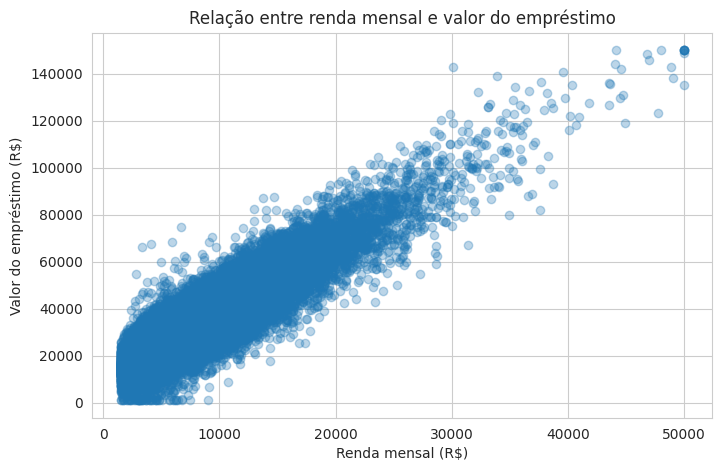

In [10]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["renda_mensal"],
    df["valor_emprestimo"],
    alpha=0.3
)

plt.xlabel("Renda mensal (R$)")
plt.ylabel("Valor do empréstimo (R$)")
plt.title("Relação entre renda mensal e valor do empréstimo")

plt.show()

O gráfico apresenta a relação entre a renda mensal e o valor do empréstimo. É possível observar uma tendência de aumento no valor do empréstimo conforme a renda mensal aumenta. Entretanto, os pontos apresentam certa dispersão, indicando que a renda mensal não é o único fator relacionado ao valor do empréstimo.

Para complementar a análise inicial, também podemos observar as principais características numéricas das variáveis por meio da função `describe()`. Essa análise permite verificar valores como média, mínimo, máximo e medidas de dispersão dos dados.


In [11]:
df.describe()

,idade,renda_mensal,score_credito,historico_pagamentos,valor_emprestimo
count,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000
mean,40.08028,7542.184144,649.581780,81.836888,31736.158491
std,10.77612,4524.255313,84.648363,11.209708,14456.325322
min,18.00000,1500.000000,300.000000,16.210000,1000.000000
25%,33.00000,4463.347500,592.000000,75.160000,22018.212500
50%,40.00000,6452.295000,650.000000,83.720000,29039.420000
75%,47.00000,9395.700000,707.000000,90.330000,38275.932500
max,70.00000,50000.000000,850.000000,100.000000,150000.000000


## Etapa 4 – Preparar os dados
Os dados serão divididos em conjunto de treinamento e conjunto de teste, utilizando a proporção de **80% para treino e 20% para teste**, o que é uma divisão amplamente utilizada em problemas de aprendizado supervisionado — garante dados suficientes para o modelo aprender os padrões e uma quantidade razoável para avaliar sua generalização.


In [12]:
from sklearn.model_selection import train_test_split

X = df.drop("valor_emprestimo", axis=1)
y = df["valor_emprestimo"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

Treinamento: (40000, 4)
Teste: (10000, 4)


##Etapa 5 – Treinar o modelo

In [13]:
from sklearn.linear_model import LinearRegression

# Criar o modelo de regressão
modelo = LinearRegression()

# Treinar o modelo com os dados de treinamento
modelo.fit(X_treino, y_treino)

# Gerar previsões usando os dados de teste
y_pred = modelo.predict(X_teste)

# Mostrar algumas previsões
print("Primeiras previsões:")
print(y_pred[:10])

Primeiras previsões:
[14806.33565684 29512.49287915 25840.73554724 21077.52290488
 27919.31404641 14530.91039368 27385.96693644 41011.6090916
 36525.08775635 35786.9609445 ]


Após o treinamento do modelo de Regressão Linear, foram geradas previsões para os dados do conjunto de teste. As cinco primeiras previsões obtidas foram aproximadamente R$ 14.806,34, R$ 29.512,49, R$ 25.840,74, R$ 21.077,52 e R$ 27.919,31.

Esses valores representam as estimativas do valor do empréstimo para os respectivos clientes do conjunto de teste. As diferenças entre os valores previstos e os valores reais serão analisadas posteriormente.


## Etapa 6 – Avaliar o modelo

Foram utilizadas duas métricas comuns para problemas de regressão:**R² (Coeficiente de Determinação)**. Também é apresentado o **MAE (Erro Absoluto Médio)** como referência adicional.

In [14]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mae = mean_absolute_error(y_teste, y_pred)
r2 = r2_score(y_teste, y_pred)

print(f"MAE (Erro Absoluto Médio): R$ {mae:,.2f}")
print(f"R² (Coeficiente de Determinação): {r2:.4f}")

MAE (Erro Absoluto Médio): R$ 2,985.94
R² (Coeficiente de Determinação): 0.9223


Para avaliar o desempenho do modelo, foram utilizadas as métricas MAE (Erro Absoluto Médio) e R² (Coeficiente de Determinação).

O MAE obtido foi de R 2.985,94. Isso significa que, considerando os dados do conjunto de teste, o modelo apresentou, em média, uma diferença de aproximadamente R$ 2.985,94 entre os valores previstos e os valores reais dos empréstimos.

O R² obtido foi de 0,9223, indicando que o modelo conseguiu explicar aproximadamente 92,23% da variação observada nos valores dos empréstimos presentes no conjunto de teste.

Esses resultados indicam que o modelo conseguiu identificar boa parte dos padrões existentes nos dados, embora ainda apresente erros nas previsões.


## Etapa 7 – Comparar valores reais e previstos

In [15]:
comparacao = pd.DataFrame({
    "Valor real": y_teste.values[:10],
    "Valor previsto": y_pred[:10]
})

comparacao["Valor real"] = comparacao["Valor real"].round(2)
comparacao["Valor previsto"] = comparacao["Valor previsto"].round(2)

comparacao

,Valor real,Valor previsto
0,22268.46,14806.34
1,27457.59,29512.49
2,25451.04,25840.74
3,23890.67,21077.52
4,27754.95,27919.31
5,12544.92,14530.91
6,28759.01,27385.97
7,46454.49,41011.61
8,43199.01,36525.09
9,34051.39,35786.96


Na comparação entre os valores reais e os valores previstos, é possível observar que algumas previsões ficaram próximas dos valores reais, enquanto outras apresentaram diferenças maiores.

Por exemplo, no terceiro registro, o valor real foi de R 25.451,04 e o valor previsto foi de R$ 25.840,74, apresentando uma diferença relativamente pequena.

Por outro lado, no primeiro registro, o valor real foi de R 22.268,46, enquanto o modelo previu R$ 14.806,34, apresentando uma diferença maior.

Esses exemplos mostram que o modelo consegue produzir previsões próximas em diversos casos, mas também pode apresentar erros consideráveis em algumas situações. Isso é esperado em um modelo de regressão e reforça a importância de analisar as métricas de avaliação juntamente com as previsões individuais.


## Etapa 8 – Fazer uma previsão


In [16]:
# Criando um novo cliente
novo_cliente = pd.DataFrame({
    "idade": [30],
    "renda_mensal": [6500],
    "score_credito": [680],
    "historico_pagamentos": [85]
})

# Fazendo a previsão
previsao = modelo.predict(novo_cliente)

print(f"Valor previsto do empréstimo: R$ {previsao[0]:,.2f}")

Valor previsto do empréstimo: R$ 30,399.11


Foi criado um novo cliente com 30 anos, renda mensal de R$ 6.500, score de crédito de 680 e histórico de pagamentos de 85%. Esses valores estão dentro dos dados utilizados no treinamento do modelo.

Para esse perfil, o modelo estimou um empréstimo de **R$ 30.399,11**.

O resultado está próximo da média dos empréstimos da base, que é de aproximadamente R$ 31.736. Isso mostra que o modelo encontrou um valor compatível com as características desse cliente. A renda mensal teve bastante influência na previsão, pois apresentou uma das maiores relações com o valor do empréstimo.

É importante lembrar que esse valor é apenas uma estimativa feita pelo modelo de Regressão Linear e não representa uma aprovação de crédito. Em uma situação real, outros fatores também seriam considerados.


## Etapa 9 – Conclusão

O modelo de Regressão Linear apresentou bons resultados para estimar os valores dos empréstimos dessa base de dados. O R² foi de **0,9223**, mostrando que o modelo conseguiu explicar aproximadamente **92,23% da variação** dos valores no conjunto de teste. O MAE foi de **R$ 2.985,94**, que representa o erro médio das previsões.

Mesmo com esses resultados, o modelo possui algumas limitações. Os valores previstos podem ser diferentes dos valores reais, como foi possível observar nas comparações feitas durante o trabalho. Além disso, foram utilizadas apenas as variáveis disponíveis na base, podendo existir outros fatores que influenciam o valor de um empréstimo.

Outra limitação é que a Regressão Linear trabalha principalmente com relações lineares. Por isso, ela pode não representar tão bem relações mais complexas entre os dados.

No geral, o modelo apresentou um resultado satisfatório para a base analisada, mas as previsões devem ser consideradas como estimativas. Para utilizar esse modelo em uma situação real, seria interessante incluir mais variáveis e testar outros modelos de regressão para comparar os resultados.
